# MetricSuite Tutorial: Autocorrelation-Aware Stats for a Few-Subject, Many-Point Study

The `noisesweep` tutorial (`metricsuite-noisesweep.ipynb`) compared methods with
**region** as the repeated-measures unit -- the right choice there because enough
regions/subjects existed to make that a meaningful, well-powered test.

`intra_vieeg_metrics/` is the opposite shape: only **4 human subjects** (far too few
for a subject-level test to have any real power -- `MetricSuite.compare_methods`
would need to treat 4 as its sample size), but each subject carries a rich per-channel
or per-timepoint curve (virtual-iEEG fidelity metrics vs. the true intracranial
recording, built by `evaluate_vieeg_fidelity` in the manuscript's
`processing_intra.qmd`). The natural instinct -- treat each channel or timepoint as
its own paired observation, *within* one subject -- runs into the same problem this
session spent a while working through: those points are **not independent**.
Measured lag-1 autocorrelation of the `wcset - competitor` difference series on this
exact data is 0.45-0.83 for timepoints and 0.16-0.52 for channels, so a plain
Wilcoxon/t-test badly overstates how much independent evidence is actually there.

This notebook applies `MetricSuite.compare_methods(..., test="ttest_ess")` -- a
paired t-test using an **effective sample size** (Thiebaux & Zwiers, 1984) computed
from the difference series' own autocorrelation, in place of the raw channel/timepoint
count -- per subject, per metric, and visualizes the result.

## 📦 - Load

Four per-subject `MetricSuite` folders, `MetricSuite.load_study`-compatible.

In [1]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import mindmap as mm

vieeg = mm.metric.MetricSuite.load_study("intra_vieeg_metrics")

REFERENCE = "wcset"
COMPETITORS = ["cset", "dspm", "sloreta", "wmne"]
# same reliability-tier ordering as the manuscript's index.qmd: sub-12/sub-50 have no
# visible interictal spike on the scalp EEG and are expected to be less reliable
SUBJECTS = ["34", "48", "12", "50"]
SUBJECT_TITLES = {"34": "sub-34", "48": "sub-48", "12": "sub-12 (no visible spike)", "50": "sub-50 (no visible spike)"}

colors = dict(zip([REFERENCE] + COMPETITORS, sns.color_palette("viridis", n_colors=5)))

df = vieeg.dataframe
print(df.columns.tolist())
print(f"{df['Subject'].nunique()} subjects, metrics: {sorted(df['Metric'].unique())}")

['Label', 'Metric', 'Value', 'Subject', 'times', 'channel']
4 subjects, metrics: ['correlation_spatial', 'correlation_spatio-temporal', 'correlation_temporal', 'cosine_spatial', 'cosine_spatio-temporal', 'cosine_temporal', 'explained_variance', 'rem_correlation_spatial', 'rem_correlation_temporal']


## 🔍 - Two metric families, two repeated-measures units

- `correlation_temporal`/`cosine_temporal`/`rem_correlation_temporal`: one value per
  **channel** (temporal correlation computed within that channel, channels as the
  free axis) -- `subject_col="channel"`.
- `correlation_spatial`/`cosine_spatial`/`rem_correlation_spatial`: one value per
  **timepoint** (spatial correlation computed at that instant, time as the free axis)
  -- `subject_col="times"`.

`"times"` is numeric, so the default pivot order (`MetricSuite.compare_methods`'s
`subject_order=None`) is already chronological -- correct out of the box. `"channel"`
is a string column, and channel names here follow the usual sEEG convention (a shaft
letter code + contact number, e.g. `"AD1", "AD2", ..., "AD10"`), so the *default*
alphabetical pivot order is wrong -- it sorts `"AD1", "AD10", "AD2", ...`, which
breaks true within-shaft contact adjacency. `natural_channel_order` fixes that by
sorting on `(shaft, contact number)` instead of the raw string -- a reasonable
approximation for adjacency *within* one shaft (consecutive contact numbers really are
physically adjacent), though ordering *between* different shafts is still arbitrary
(there's no single natural 1D order for electrodes implanted along different
trajectories). Getting true 3D geometric adjacency would need the electrode positions
`compute_virtual_ieeg` used, which aren't saved in this `MetricSuite` -- out of scope
here, this is a documented approximation, not a solved problem.

In [2]:
def natural_channel_order(channels):
    def key(ch):
        m = re.match(r"([A-Za-z]+)(\d+)", ch)
        return (m.group(1), int(m.group(2))) if m else (ch, 0)
    return sorted(channels, key=key)


print("alphabetical:", sorted(df[df["Subject"] == "48"]["channel"].dropna().unique())[:8])
print("natural sort:", natural_channel_order(df[df["Subject"] == "48"]["channel"].dropna().unique())[:8])

alphabetical: ['AD1', 'AD10', 'AD2', 'AD3', 'AD4', 'AD6', 'AD7', 'AD8']
natural sort: ['AD1', 'AD2', 'AD3', 'AD4', 'AD6', 'AD7', 'AD8', 'AD9']


## 🧪 - One comparison, in detail

`sub-12`'s `correlation_spatial` (timepoints) is a good illustration of why this
matters: the raw count of timepoints makes a plain test look strongly significant,
which mostly evaporates once the effective sample size properly discounts for
autocorrelation.

In [3]:
result_wilcoxon = vieeg.compare_methods(
    "correlation_spatial", reference=REFERENCE, subject_col="times",
    labels=[REFERENCE, "cset"], subjects="12", test="wilcoxon",
)
result_ess = vieeg.compare_methods(
    "correlation_spatial", reference=REFERENCE, subject_col="times",
    labels=[REFERENCE, "cset"], subjects="12", test="ttest_ess",
)
print("plain wilcoxon:")
print(result_wilcoxon[["Label", "n_pairs", "p_value", "significant"]])
print()
print("ESS-corrected ttest:")
print(result_ess[["Label", "n_pairs", "n_eff", "p_value", "significant"]])

plain wilcoxon:
  Label  n_pairs   p_value  significant
0  cset      124  0.000664         True

ESS-corrected ttest:
  Label  n_pairs      n_eff   p_value  significant
0  cset      124  25.436955  0.122801        False


## 📊 - Every subject, every metric family, every competitor

Two ways of showing "does wCSET beat this competitor" were on the table: a **win-rate
matrix** (fraction of channels/timepoints where one method beats another, the
manuscript's own `results_intra_vieeg_winrate.py` approach) versus plotting the
**paired differences themselves** to see whether they skew positive or negative. This
combines both into one panel per `(subject, metric family)`: a box+strip of the
`wCSET - competitor` difference at every channel/timepoint (green dots above zero =
wCSET wins there, red = competitor wins), annotated with the win-rate *relative to the
50% chance line* (`+17%`/`-13%`, colored to match -- quicker to read than a raw `67%`
vs. `37%`, which both need mentally subtracting 50% first to tell which way they lean)
and the ESS-corrected significance (stars) and `n_eff` -- so the plot shows both "how
many points improve, and by how much more than a coin flip" and "is that shift big
enough, given how much independent evidence `n_eff` says there actually is, to trust
as more than noise."

In [4]:
def paired_diffs(subject, metric, coord, subject_order=None):
    df_sub = vieeg.get_filtered_df(metrics=metric, subjects=subject)
    wide = df_sub.pivot(index=coord, columns="Label", values="Value")
    if subject_order is not None:
        wide = wide.reindex(subject_order)
    wide = wide.dropna(subset=[REFERENCE] + COMPETITORS)
    diffs = {c: (wide[REFERENCE] - wide[c]).to_numpy() for c in COMPETITORS}
    return diffs, wide.index.tolist()


def plot_diff_panel(ax, subject, metric, coord, subject_order=None, title=None):
    diffs, order = paired_diffs(subject, metric, coord, subject_order)
    results = vieeg.compare_methods(
        metric, reference=REFERENCE, subject_col=coord, subjects=subject,
        test="ttest_ess", subject_order=order, labels=[REFERENCE] + COMPETITORS,
    )

    data = [diffs[c] for c in COMPETITORS]
    bp = ax.boxplot(data, positions=range(len(COMPETITORS)), widths=0.5,
                     patch_artist=True, showfliers=False, zorder=2)
    for patch, c in zip(bp["boxes"], COMPETITORS):
        patch.set_facecolor(colors[c])
        patch.set_alpha(0.55)
    for element in ["whiskers", "caps", "medians"]:
        for line in bp[element]:
            line.set_color("#333333")

    rng = np.random.default_rng(0)
    for i, c in enumerate(COMPETITORS):
        y = diffs[c]
        x = i + rng.uniform(-0.15, 0.15, size=len(y))
        point_colors = np.where(y > 0, "tab:green", "tab:red")
        ax.scatter(x, y, s=6, alpha=0.45, c=point_colors, linewidths=0, zorder=3)

    ax.axhline(0, color="black", linewidth=1, linestyle="--", zorder=1)
    ax.set_xticks(range(len(COMPETITORS)))
    ax.set_xticklabels(COMPETITORS, fontsize=8)

    ymax, ymin = max(np.max(d) for d in data), min(np.min(d) for d in data)
    span = ymax - ymin
    for i, c in enumerate(COMPETITORS):
        row = results[results["Label"] == c].iloc[0]
        # relative to the 50% chance line, not the raw win-rate -- +17%/-13% reads
        # instantly (sign + color = direction, magnitude = how far from a coin flip),
        # where "37% vs. 67%" both need mentally subtracting 50% first to compare
        rel_win = (diffs[c] > 0).mean() - 0.5
        p = row["p_corrected"]
        stars = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
        win_color = "tab:green" if rel_win > 0 else "tab:red"
        ax.text(i, ymax + 0.10 * span, stars, ha="center", va="bottom", fontsize=7, color="#222222")
        ax.text(i, ymax + 0.055 * span, f"{rel_win:+.0%}", ha="center", va="bottom",
                fontsize=7.5, color=win_color, fontweight="bold")
        ax.text(i, ymax + 0.01 * span, f"n_eff={row['n_eff']:.0f}", ha="center", va="bottom",
                fontsize=6, color="#666666")

    ax.set_ylim(ymin - 0.08 * span, ymax + 0.32 * span)
    if title:
        ax.set_title(title, fontsize=9)

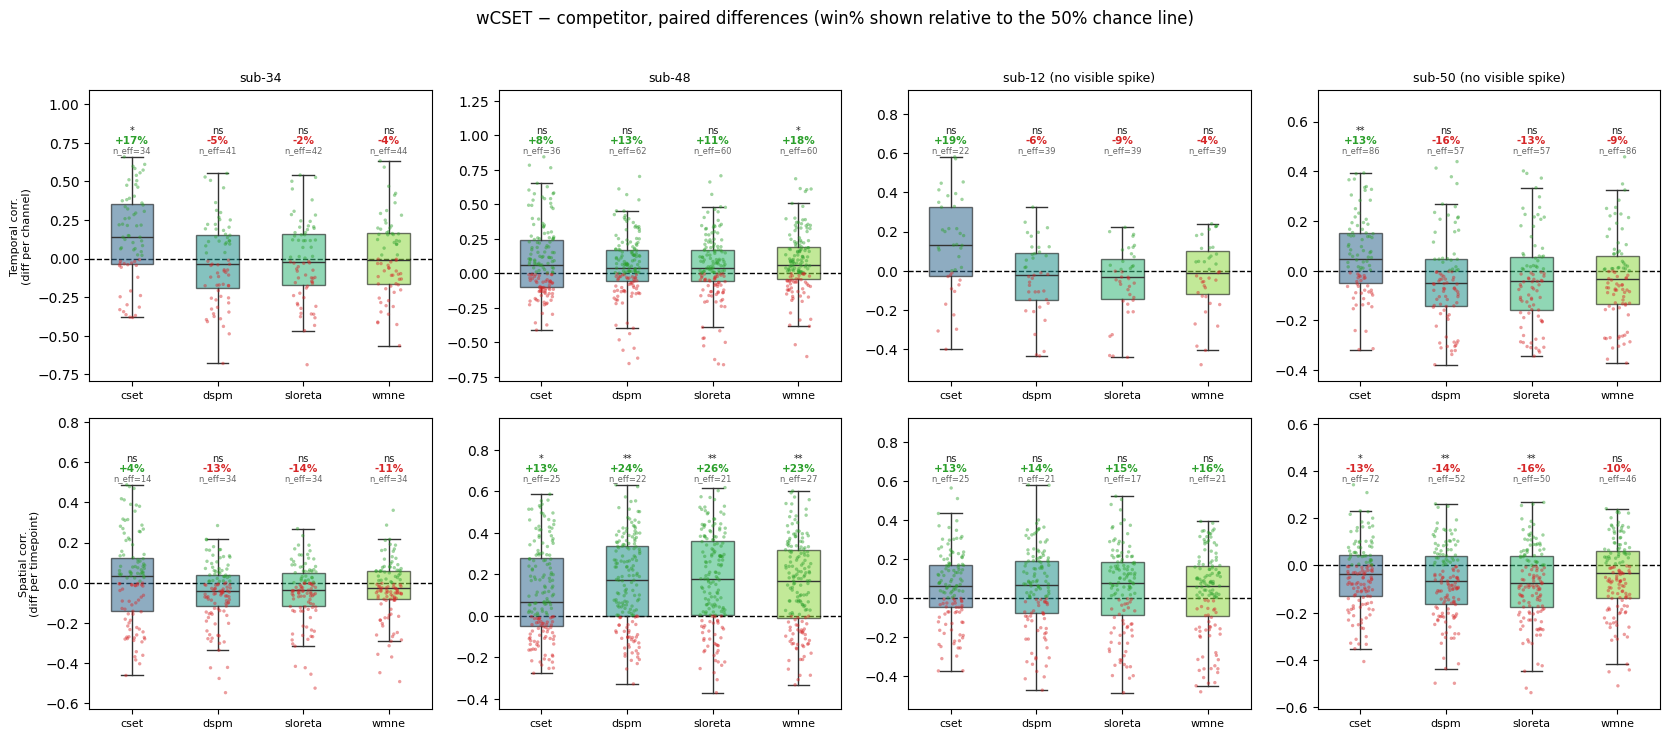

In [5]:
METRIC_BLOCKS = [
    ("correlation_temporal", "channel", "Temporal corr.\n(diff per channel)"),
    ("correlation_spatial", "times", "Spatial corr.\n(diff per timepoint)"),
]

fig, axes = plt.subplots(len(METRIC_BLOCKS), len(SUBJECTS), figsize=(4.2 * len(SUBJECTS), 3.6 * len(METRIC_BLOCKS)))

for row_i, (metric, coord, ylabel) in enumerate(METRIC_BLOCKS):
    for col_i, sub in enumerate(SUBJECTS):
        ax = axes[row_i, col_i]
        subject_order = None
        if coord == "channel":
            chans = vieeg.get_filtered_df(metrics=metric, subjects=sub)["channel"].dropna().unique().tolist()
            subject_order = natural_channel_order(chans)
        plot_diff_panel(ax, sub, metric, coord, subject_order=subject_order,
                         title=SUBJECT_TITLES[sub] if row_i == 0 else None)
        if col_i == 0:
            ax.set_ylabel(ylabel, fontsize=8)

fig.suptitle("wCSET − competitor, paired differences (win% shown relative to the 50% chance line)", y=1.02)
fig.tight_layout()

## Reading the result

A few things pop out that a purely subject-averaged (Cleveland dot plot) figure
would hide:

- **sub-12 and sub-50** (no visible scalp spike) come back mostly `ns` despite
  win-rates that aren't at chance (e.g. sub-12 temporal vs. dspm: -6%, clearly `ns`)
  -- consistent with the manuscript's own reliability-tier caveat about these two
  subjects, now backed by a properly-corrected test rather than just a prior.
- Win-rate and significance can disagree: a competitor can win a solid majority of
  timepoints/channels and still come back `ns` once `n_eff` discounts for
  autocorrelation (e.g. sub-48 temporal vs. cset: +8%, `ns`), and conversely a
  smaller-looking shift with lower autocorrelation can still clear the bar. The
  win-rate alone (the manuscript's matrix) can't distinguish those two cases; this
  plot can.

## Wrap-up

- `MetricSuite.compare_methods(..., test="ttest_ess", subject_col=..., subject_order=...)`
  -- paired t-test with an autocorrelation-corrected effective sample size, for
  repeated-measures units (channels, timepoints) that have real serial correlation.
- `subject_order` matters whenever the natural sort of `subject_col` doesn't reflect
  true adjacency (channels) -- harmless to omit when it does (numeric coordinates
  like `"times"`).
- The difference-distribution + win-rate panel above answers "how many points
  improve" (the win-rate matrix's question) and "is the shift large/consistent enough
  to trust" (the ESS-corrected test's question) in one figure, per subject.

See `mindmap/core/stats.py` (`effective_sample_size`, `paired_test`) and
`mindmap/analysis/stats.py`/`mindmap/metric/base.py` (`compare_methods`) for the full
implementation, and `tutorials/analysis/metrics/metricsuite-noisesweep.ipynb` for the
region-as-subject / many-subjects counterpart to this notebook.